# 02. Pressures and status: what the raw data already says, and why it cannot be read directly

Before any model: how does status vary with each pressure, and which pressures travel together?

In [1]:
import sys, warnings, json
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (9, 4.2), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
T = ROOT / "outputs" / "tables"; FIG = ROOT / "outputs" / "figures"
from river_health import modeling as M
t = M.prepare(pd.read_parquet(ROOT / "data" / "processed" / "river_features.parquet"))

In [2]:
for tgt, lab in [("y_eco", "ecological"), ("y_inv", "invertebrates"), ("y_phos", "phosphate"), ("y_fish", "fish")]:
    print(f"{lab:14s}", t[tgt].value_counts(normalize=True).reindex(["High", "Good", "Moderate", "Poor", "Bad"]).round(3).to_dict())

ecological     {'High': 0.001, 'Good': 0.149, 'Moderate': 0.622, 'Poor': 0.193, 'Bad': 0.035}
invertebrates  {'High': 0.425, 'Good': 0.333, 'Moderate': 0.164, 'Poor': 0.054, 'Bad': 0.023}
phosphate      {'High': 0.285, 'Good': 0.199, 'Moderate': 0.298, 'Poor': 0.204, 'Bad': 0.014}
fish           {'High': 0.14, 'Good': 0.283, 'Moderate': 0.267, 'Poor': 0.248, 'Bad': 0.062}


## Status by fifth of upstream spill intensity

In [3]:
q = pd.qcut(t.up_spill_hours_per_km2.rank(method="first"), 5, labels=["lowest", "2", "3", "4", "highest"])
tab = pd.DataFrame({
    "spill h/km2 (median)": t.groupby(q).up_spill_hours_per_km2.median(),
    "eco good": t.groupby(q).y_eco_good.mean(), "invertebrates good": t.groupby(q).y_inv_good.mean(),
    "phosphate good": t.groupby(q).phos_good.mean(), "urban share": t.groupby(q).up_lc_urban.mean(),
    "sewage works DWF/km2": t.groupby(q).up_stw_dwf_m3d_per_km2.median()})
tab.round(3)

,spill h/km2 (median),eco good,invertebrates good,phosphate good,urban share,sewage works DWF/km2
up_spill_hours_per_km2,,,,,,
lowest,0.000,0.269,0.813,0.685,0.029,0.000
2,0.000,0.198,0.781,0.589,0.051,0.000
3,7.483,0.105,0.770,0.422,0.060,6.194
4,21.226,0.104,0.759,0.373,0.067,14.294
highest,54.272,0.077,0.673,0.353,0.080,21.205


Status worsens as spills rise, but so does everything else: the catchments with the most spills are
also the most urban and receive the most treated sewage. Read alone, this table would credit overflows
with the effect of towns and sewage works. That confounding is the central difficulty of the project.

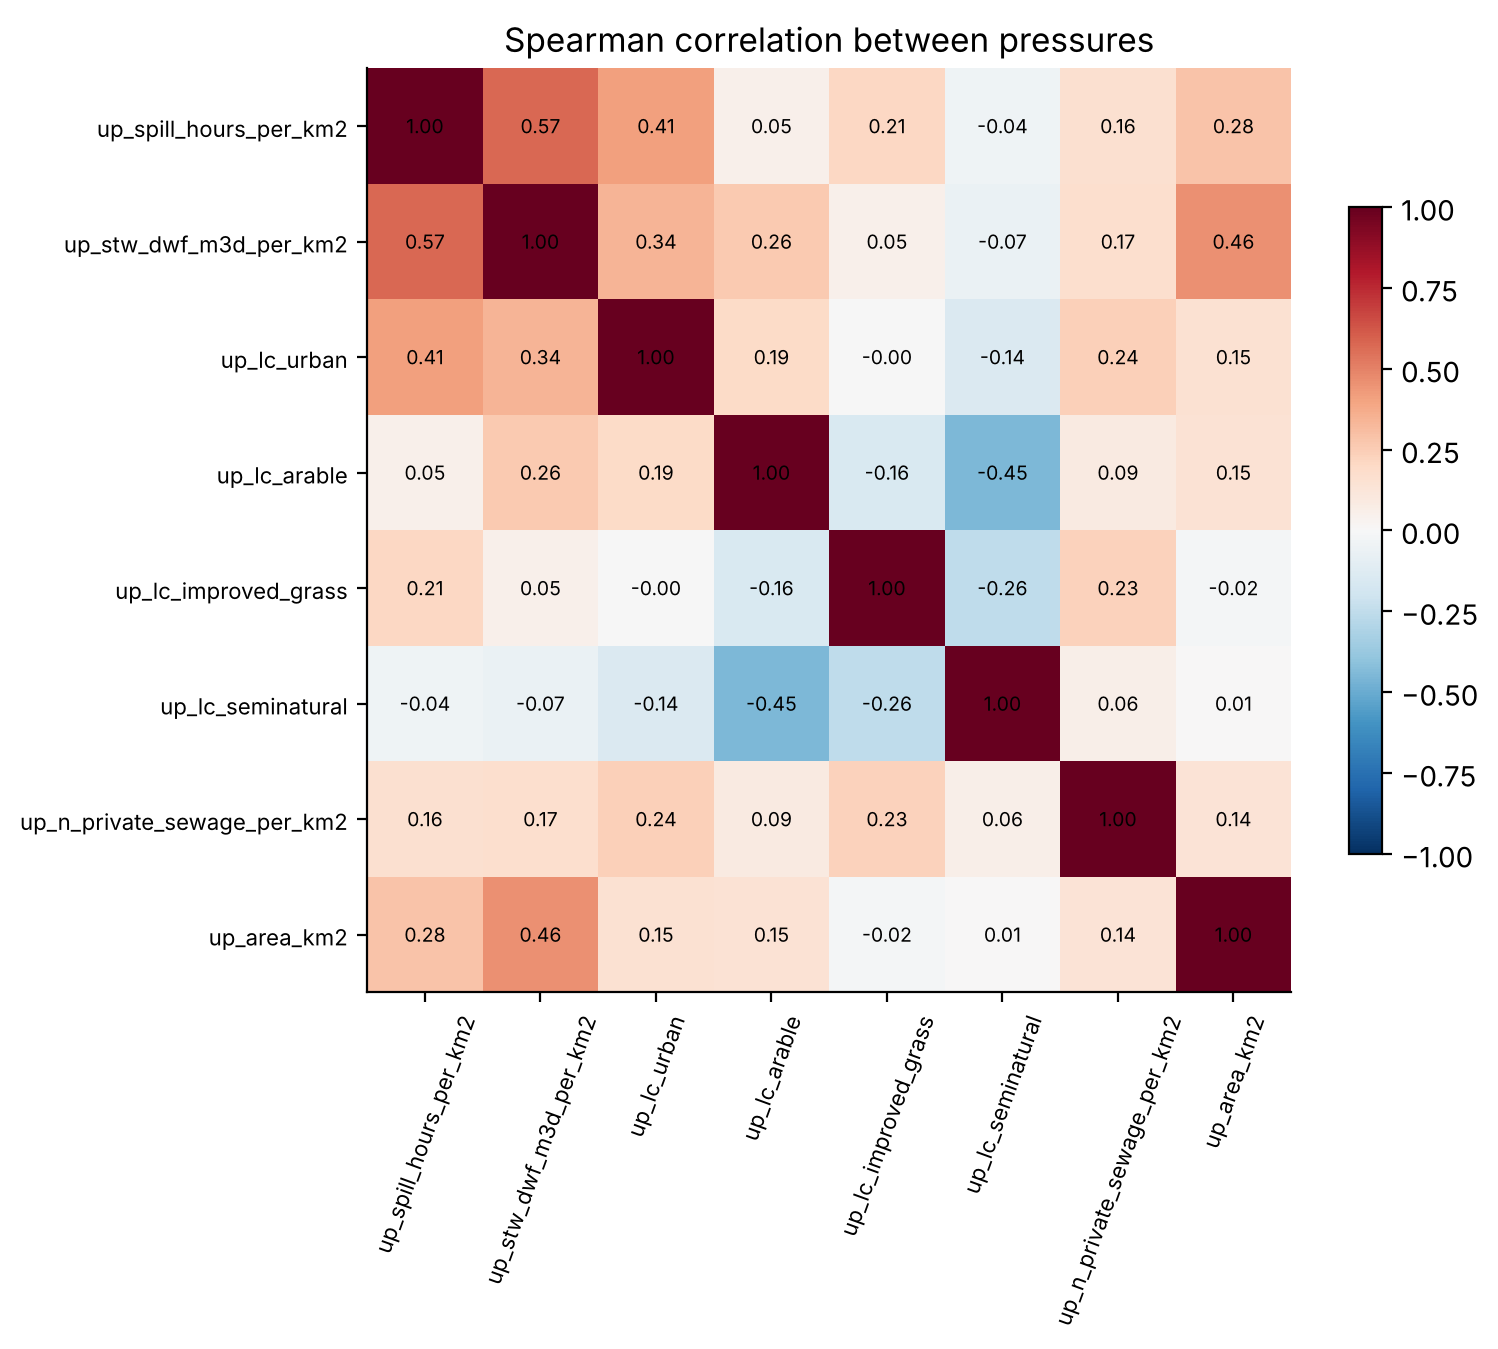

In [4]:
cols = ["up_spill_hours_per_km2", "up_stw_dwf_m3d_per_km2", "up_lc_urban", "up_lc_arable",
        "up_lc_improved_grass", "up_lc_seminatural", "up_n_private_sewage_per_km2", "up_area_km2"]
c = t[cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(c, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=70, fontsize=8)
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols, fontsize=8); ax.grid(False)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{c.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, shrink=0.7); plt.title("Spearman correlation between pressures"); plt.show()

## Rank correlations with each target

In [5]:
num = [f for f in M.PRESSURE_SET if f not in M.CATEGORICAL] + M.CHEMISTRY
r = t[num + ["y_eco_code", "y_inv_code", "y_phos_code", "y_fish_code"]].corr(method="spearman").loc[
    num, ["y_eco_code", "y_inv_code", "y_phos_code", "y_fish_code"]]
r.sort_values("y_phos_code").round(2)

,y_eco_code,y_inv_code,y_phos_code,y_fish_code
chem_orthophosphate_mgP,-0.30,-0.30,-0.79,-0.12
chem_ammonia_mgN,-0.23,-0.44,-0.51,-0.20
up_lc_urban,-0.23,-0.36,-0.47,-0.15
up_stw_dwf_m3d_per_km2,-0.17,-0.06,-0.43,0.02
local_lc_urban,-0.21,-0.34,-0.42,-0.13
chem_nitrate_mgN,-0.22,-0.09,-0.41,-0.13
local_stw_dwf_m3d,-0.15,-0.03,-0.35,0.03
up_spill_hours_per_km2,-0.14,-0.11,-0.31,0.00
up_lc_arable,-0.22,-0.08,-0.30,-0.15
up_spill_count_per_km2,-0.13,-0.16,-0.30,-0.01


* **Phosphate** follows sewage works effluent (per km² upstream), urban land and arable land.
* **Invertebrates** follow urban land and measured ammonia and BOD: classic organic pollution.
* **Fish** correlate weakly with everything here. Barriers, flow and habitat are not in the data.
* Measured **chemistry** correlates more strongly than any pressure, as it should: it is the route by which
  pressures reach the biology. The models therefore use pressures only, and keep chemistry as a diagnostic
  (notebook 05), so that their explanations are about *what to manage*.

In [6]:
pd.crosstab(t.hmwb, t.y_eco, normalize="index").reindex(columns=["High", "Good", "Moderate", "Poor", "Bad"]).round(3)

y_eco,High,Good,Moderate,Poor,Bad
hmwb,,,,,
artificial,0.000,0.018,0.909,0.045,0.027
heavily_modified,0.000,0.064,0.858,0.063,0.015
natural,0.002,0.192,0.506,0.256,0.044
